# 02 การสำรวจข้อมูลเบื้องต้น (EDA) บนข้อมูลดิบ

**เป้าหมาย:** อธิบายคุณภาพของ snapshot ดิบแต่ละปี ก่อนการทำความสะอาด: จำนวนแถว, ค่าว่าง, ID ไม่ซ้ำ/ซ้ำ, รูปแบบวันที่/เวลา, คุณภาพพิกัด, การกระจายของหมวดหมู่ และความครอบคลุมรายเดือน/รายชั่วโมงเฉพาะแถวที่รูปแบบยืนยันได้

**อินพุต:** `data/raw/accidents/*.csv` + `source_manifest.json` จาก Notebook 01 (ตรวจ SHA256 ทุกไฟล์ก่อนอ่าน)

**การแปลง:** ไม่มีการแก้ข้อมูล ใช้การจัดกลุ่มชื่อคอลัมน์ (alias) เพื่อเปรียบเทียบข้ามปีแบบพรรณนาเท่านั้น — นี่คือ **ข้อมูลดิบ ไม่ใช่ข้อมูลที่ทำความสะอาดแล้ว**

**เอาต์พุต:** `reports/data/eda/*.csv` และ `*.png`

**การตรวจสอบ:** ผลรวมแถวในตาราง EDA = จำนวนแถวใน manifest; hash ของ snapshot ตรงกับ manifest

**ข้อจำกัด:** จำนวนรายงานเป็นศูนย์ไม่ได้แปลว่าไม่มีอุบัติเหตุ; ความสัมพันธ์ที่เห็นไม่ใช่เหตุและผล; การดูข้อมูลปี 2024–2026 ที่นี่ทำให้ข้อมูลเหล่านั้นไม่ใช่ข้อมูลที่ "ไม่เคยถูกมอง" อีกต่อไป (บันทึกไว้ใน Notebook 05); เดือน/ชั่วโมงในขั้นนี้ **ได้จากรูปแบบค่า** (format-derived) และตรวจเพียงว่าเป็นวันที่/เวลาที่มีอยู่จริง ไม่ใช่วันที่ที่ผ่านการตรวจเต็มรูปแบบของ Notebook 03 (เช่น ไม่ได้ตรวจว่าปีตรงกับไฟล์)

**สัญญาสำหรับขั้นถัดไป:** Notebook 03 ใช้ข้อค้นพบนี้ (เช่น วันที่กำกวม, Excel serial ปี 2567/2568, ไม่มี ACC_CODE ปี 2569) ในการออกแบบกฎแบบระมัดระวัง

In [1]:
import os, sys, json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

def find_backend_root():
    env = os.environ.get('ROADAWARE_BACKEND_ROOT')
    if env:
        return Path(env).resolve()
    here = Path.cwd().resolve()
    for c in [here, *here.parents]:
        if (c / 'backend' / 'config' / 'data_pipeline.json').is_file():
            return c / 'backend'
        if c.name == 'backend' and (c / 'config' / 'data_pipeline.json').is_file():
            return c
    raise FileNotFoundError('backend/config/data_pipeline.json not found from ' + str(here) + '; open the repository root or backend/notebooks')

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(chunk), b''):
            h.update(b)
    return h.hexdigest()

def verify_hashes(base, entries, label):
    bad = []
    for e in entries:
        p = base / e['path']
        if not p.is_file():
            bad.append('missing ' + str(p))
        elif sha256_file(p) != e['sha256']:
            bad.append('sha256 mismatch ' + str(p))
    if bad:
        raise RuntimeError(label + ' failed verification; rerun the producing notebook or use a fresh --output-dir:\n' + '\n'.join(bad))
    return len(entries)

BACKEND = find_backend_root()
REPO = BACKEND.parent
CFG = json.loads((BACKEND / 'config' / 'data_pipeline.json').read_text('utf-8'))
OUT = Path(os.environ.get('ROADAWARE_OUTPUT_DIR') or (BACKEND / CFG['output_root'])).resolve()
if os.environ.get('ROADAWARE_REQUIRE_VENV') == '1':
    assert Path(sys.prefix).resolve() == (REPO / '.venv').resolve(), 'kernel is not the project .venv: ' + sys.executable
RAW, REP = OUT / 'data' / 'raw' / 'accidents', OUT / 'reports' / 'data'
EDA = REP / 'eda'
EDA.mkdir(parents=True, exist_ok=True)
man_file = RAW / 'source_manifest.json'
if not man_file.is_file():
    raise FileNotFoundError(str(man_file) + ' missing; run 01_data_collection first')
MAN = json.loads(man_file.read_text('utf-8'))
print('verified raw snapshots:', verify_hashes(OUT, MAN['files'], 'raw snapshot'))
thai_fonts = [f.name for f in font_manager.fontManager.ttflist if f.name in ('Thonburi', 'Tahoma', 'Noto Sans Thai', 'Ayuthaya')]
if thai_fonts:
    plt.rcParams['font.family'] = [thai_fonts[0], 'DejaVu Sans']
print('plot font:', plt.rcParams['font.family'])

verified raw snapshots: 6
plot font: ['Tahoma', 'DejaVu Sans']


In [2]:
# FUNCTIONS (notebook 02) - descriptive classifiers only; the authoritative parser lives in notebook 03
import numpy as np, pandas as pd

def norm_text(s):
    return s.fillna('').astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()

def pick(df, aliases):
    hit = [n for n in aliases if n in df.columns]
    return norm_text(df[hit[0]]) if hit else None

def slash_parts(s):
    sl = s.str.extract(r'^(\d{1,2})/(\d{1,2})/(\d{4})$')
    return sl[0].notna(), pd.to_numeric(sl[0]), pd.to_numeric(sl[1])

def hh_mm_parts(s):
    """(matches HH:MM[:SS] text, value is a real clock time 00:00:00-23:59:59, hour)."""
    hm = s.str.extract(r'^(\d{1,2}):(\d{2})(?::(\d{2}))?$').apply(pd.to_numeric)
    is_hm = hm[0].notna()
    valid = is_hm & (hm[0] < 24) & (hm[1] < 60) & (hm[2].fillna(0) < 60)
    return is_hm, valid, hm[0]

def classify_date_format(s):
    s = norm_text(s)
    out = pd.Series('other', index=s.index)
    out[s == ''] = 'empty'
    out[s.str.fullmatch(r'\d+(\.0+)?')] = 'excel_serial_like'
    out[s.str.fullmatch(r'\d{4}-\d{1,2}-\d{1,2}')] = 'iso'
    is_sl, a, b = slash_parts(s)
    out[is_sl & (a > 12) & (b <= 12)] = 'slash_first_gt12'
    out[is_sl & (b > 12) & (a <= 12)] = 'slash_second_gt12'
    out[is_sl & (a == b)] = 'slash_equal_parts'
    out[is_sl & (a <= 12) & (b <= 12) & (a != b)] = 'slash_ambiguous'
    out[is_sl & (a > 12) & (b > 12)] = 'slash_invalid'
    return out

def classify_time_format(s):
    s = norm_text(s)
    out = pd.Series('other', index=s.index)
    out[s == ''] = 'empty'
    x = pd.to_numeric(s, errors='coerce')
    out[np.isfinite(x) & (x >= 0) & (x < 1)] = 'excel_fraction'
    is_hm, valid, _ = hh_mm_parts(s)
    out[is_hm & valid] = 'hh_mm'
    out[is_hm & ~valid] = 'hh_mm_out_of_range'
    return out

def confirmed_month(s):
    """Format-derived month: only where the value pins the month down (Excel serial, slash with a part > 12, equal parts)
    AND day/month/year form a real calendar date. Descriptive only; the year-match check is done in notebook 03."""
    s = norm_text(s)
    month = pd.Series(np.nan, index=s.index)
    ser = pd.to_numeric(s.where(s.str.fullmatch(r'\d+(\.0+)?')), errors='coerce')
    ok = ser.between(30000, 60000)
    month[ok] = (pd.Timestamp('1899-12-30') + pd.to_timedelta(ser[ok].astype('int64'), unit='D')).dt.month
    is_sl, a, b = slash_parts(s)
    yr = pd.to_numeric(s.str.extract(r'^\d{1,2}/\d{1,2}/(\d{4})$')[0], errors='coerce')
    yr = yr.where(~(yr > 2400), yr - 543)  # Buddhist-era years
    day, mon = pd.Series(np.nan, index=s.index), pd.Series(np.nan, index=s.index)
    for m, d_part, m_part in ((is_sl & (a > 12) & (b <= 12), a, b), (is_sl & (b > 12) & (a <= 12), b, a), (is_sl & (a == b) & (a <= 12), a, a)):
        day[m], mon[m] = d_part[m], m_part[m]
    sel = day.notna() & mon.notna() & yr.notna()
    if sel.any():
        ymd = pd.DataFrame({'year': yr[sel].astype('int64'), 'month': mon[sel].astype('int64'), 'day': day[sel].astype('int64')})
        real = pd.to_datetime(ymd, errors='coerce')  # impossible dates such as 31/02 -> NaT
        keep = real[real.notna()].index
        month[keep] = mon[keep]
    return month

def confirmed_hour(s):
    """Hour only for real clock times (HH<24, MM<60, SS<60) or Excel day fractions that do not round to the next midnight."""
    s = norm_text(s)
    hour = pd.Series(np.nan, index=s.index)
    x = pd.to_numeric(s, errors='coerce')
    frac = np.isfinite(x) & (x >= 0) & (x < 1)
    sec = (x[frac] * 86400).round()
    hour[frac] = np.where(sec < 86400, np.floor(sec / 3600), np.nan)
    _, valid, hh = hh_mm_parts(s)
    hour[valid] = hh[valid]
    return hour

In [3]:
AL = CFG['schema_aliases']
bbox = CFG['thailand_bbox']
frames, overview = {}, []
for f in MAN['files']:
    raw = pd.read_csv(RAW / f['file'], dtype=str, keep_default_na=False, encoding=f['encoding'])
    assert len(raw) == f['rows'], f['file']
    frames[f['be_year']] = raw
    acc = pick(raw, AL['acc_code'])
    lat = pd.to_numeric(pick(raw, AL['latitude']), errors='coerce')
    lon = pd.to_numeric(pick(raw, AL['longitude']), errors='coerce')
    finite = np.isfinite(lat) & np.isfinite(lon)
    inside = finite & lat.between(bbox['lat_min'], bbox['lat_max']) & lon.between(bbox['lon_min'], bbox['lon_max'])
    tnorm = pick(raw, AL['time_raw'])
    overview.append({
        'be_year': f['be_year'], 'rows': len(raw), 'n_columns': raw.shape[1],
        'acc_code_column': acc is not None,
        'acc_code_nonempty': int((acc != '').sum()) if acc is not None else 0,
        'acc_code_unique': int(acc[acc != ''].nunique()) if acc is not None else 0,
        'rows_in_repeated_acc_code': int(acc[acc != ''].duplicated(keep=False).sum()) if acc is not None else 0,
        'exact_duplicate_rows': int(raw.duplicated(keep=False).sum()),
        'coord_finite': int(finite.sum()), 'coord_missing_or_nonnumeric': int((~finite).sum()),
        'coord_outside_broad_bbox': int((finite & ~inside).sum()),
        'time_exact_midnight_share': round(float(((tnorm == '0:00') | (tnorm == '00:00') | (pd.to_numeric(tnorm, errors='coerce') == 0)).mean()), 4),
        'province_empty': int((pick(raw, AL['province']) == '').sum()),
    })
overview = pd.DataFrame(overview).set_index('be_year')
overview.to_csv(EDA / 'raw_overview_by_year.csv')
overview

,rows,n_columns,acc_code_column,acc_code_nonempty,acc_code_unique,rows_in_repeated_acc_code,exact_duplicate_rows,coord_finite,coord_missing_or_nonnumeric,coord_outside_broad_bbox,time_exact_midnight_share,province_empty
be_year,,,,,,,,,,,,
2564,20062,38,True,20062,20062,0,0,19997,65,0,0.0017,2
2565,20566,38,True,20566,20566,0,0,20493,73,0,0.0012,1
2566,23841,38,True,23841,22139,3343,122,23665,176,4,0.0020,14
2567,23952,38,True,23952,23952,0,0,23714,238,0,0.0017,1929
2568,23715,38,True,23715,23715,0,0,23546,169,2,0.0017,6
2569,15239,38,False,0,0,0,44,15088,151,0,0.0014,1


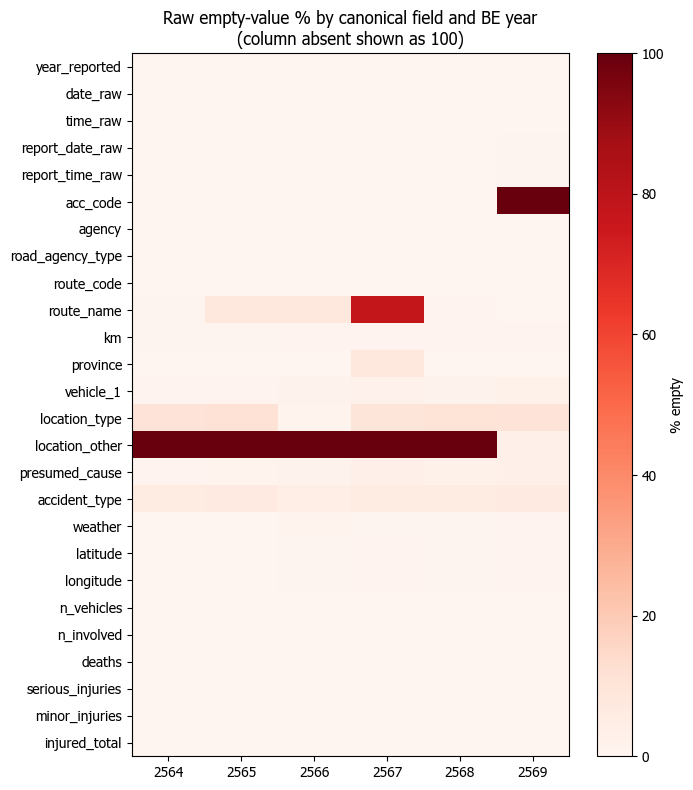

,2564,2565,2566,2567,2568,2569
year_reported,0.00,0.00,0.00,0.00,0.00,0.00
date_raw,0.00,0.00,0.00,0.00,0.00,0.00
time_raw,0.00,0.00,0.00,0.00,0.00,0.00
report_date_raw,0.00,0.00,0.02,0.00,0.00,0.49
report_time_raw,0.00,0.02,0.02,0.00,0.00,0.49
acc_code,0.00,0.00,0.00,0.00,0.00,NaN
agency,0.00,0.00,0.00,0.00,0.00,0.00
road_agency_type,0.00,0.00,0.00,0.00,0.00,0.00
route_code,0.00,0.00,0.00,0.01,0.04,0.00
route_name,0.43,7.48,7.55,77.40,0.86,0.16


In [4]:
miss = {}
for y, raw in frames.items():
    miss[y] = {k: (round(float((pick(raw, v) == '').mean()) * 100, 2) if pick(raw, v) is not None else np.nan) for k, v in AL.items()}
miss = pd.DataFrame(miss)
miss.to_csv(EDA / 'raw_missing_percent_by_field_year.csv')
fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(miss.fillna(100).values, aspect='auto', cmap='Reds', vmin=0, vmax=100)
ax.set_xticks(range(miss.shape[1])); ax.set_xticklabels(miss.columns)
ax.set_yticks(range(miss.shape[0])); ax.set_yticklabels(miss.index)
ax.set_title('Raw empty-value % by canonical field and BE year\n(column absent shown as 100)')
fig.colorbar(im, ax=ax, label='% empty')
fig.tight_layout(); fig.savefig(EDA / 'raw_missing_heatmap.png', dpi=120); plt.show()
miss

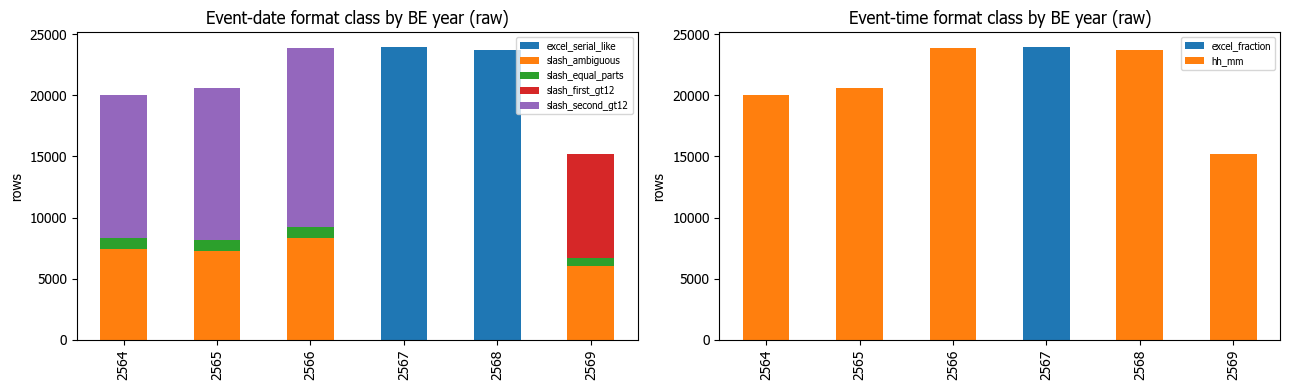

slash_first_gt12 implies D/M order; slash_second_gt12 implies M/D order; slash_ambiguous cannot be decided from the value alone
hh_mm = real clock time; hh_mm_out_of_range = HH:MM text with HH>=24, MM>=60 or SS>=60 (e.g. 24:00, 12:99)


,2564,2565,2566,2567,2568,2569
excel_serial_like,0,0,0,23952,23715,0
slash_ambiguous,7413,7268,8295,0,0,6034
slash_equal_parts,898,867,968,0,0,683
slash_first_gt12,0,0,0,0,0,8522
slash_second_gt12,11751,12431,14578,0,0,0


,2564,2565,2566,2567,2568,2569
excel_fraction,0,0,0,23952,0,0
hh_mm,20062,20566,23841,0,23715,15239


In [5]:
dfmt = pd.DataFrame({y: classify_date_format(pick(raw, AL['date_raw'])).value_counts() for y, raw in frames.items()}).fillna(0).astype(int)
tfmt = pd.DataFrame({y: classify_time_format(pick(raw, AL['time_raw'])).value_counts() for y, raw in frames.items()}).fillna(0).astype(int)
dfmt.to_csv(EDA / 'raw_date_format_by_year.csv'); tfmt.to_csv(EDA / 'raw_time_format_by_year.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
dfmt.T.plot(kind='bar', stacked=True, ax=axes[0], title='Event-date format class by BE year (raw)')
tfmt.T.plot(kind='bar', stacked=True, ax=axes[1], title='Event-time format class by BE year (raw)')
for a in axes:
    a.set_ylabel('rows'); a.legend(fontsize=7)
fig.tight_layout(); fig.savefig(EDA / 'raw_date_time_formats.png', dpi=120); plt.show()
print('slash_first_gt12 implies D/M order; slash_second_gt12 implies M/D order; slash_ambiguous cannot be decided from the value alone')
print('hh_mm = real clock time; hh_mm_out_of_range = HH:MM text with HH>=24, MM>=60 or SS>=60 (e.g. 24:00, 12:99)')
display(dfmt); display(tfmt)

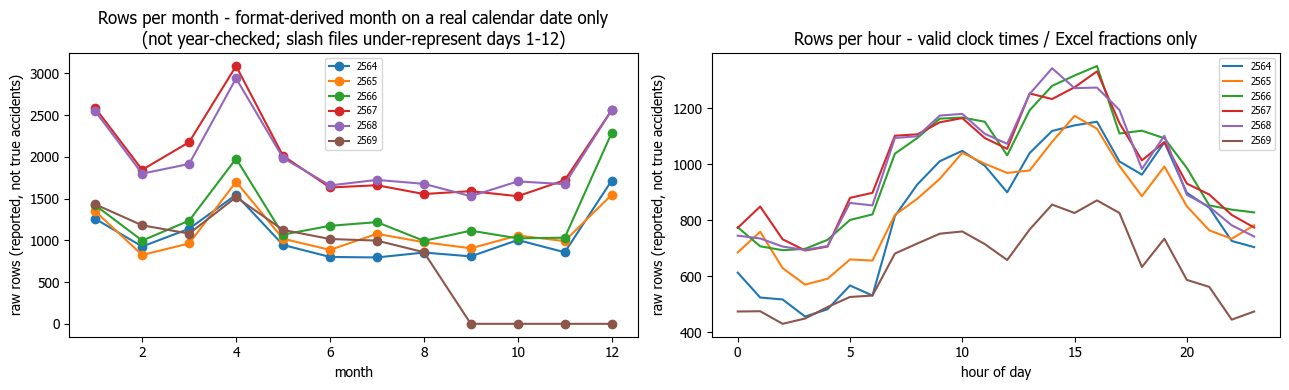

,rows,format_derived_month_rows,valid_hour_rows
2564,20062,12649,20062
2565,20566,13298,20566
2566,23841,15546,23841
2567,23952,23952,23952
2568,23715,23715,23715
2569,15239,9205,15239


In [6]:
mon = pd.DataFrame({y: confirmed_month(pick(raw, AL['date_raw'])).value_counts().reindex(range(1, 13), fill_value=0) for y, raw in frames.items()})
hrs = pd.DataFrame({y: confirmed_hour(pick(raw, AL['time_raw'])).value_counts().reindex(range(24), fill_value=0) for y, raw in frames.items()})
mon.to_csv(EDA / 'raw_confirmed_month_coverage.csv'); hrs.to_csv(EDA / 'raw_confirmed_hour_coverage.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mon.plot(ax=axes[0], marker='o', title='Rows per month - format-derived month on a real calendar date only\n(not year-checked; slash files under-represent days 1-12)')
hrs.plot(ax=axes[1], title='Rows per hour - valid clock times / Excel fractions only')
axes[0].set_xlabel('month'); axes[1].set_xlabel('hour of day')
for a in axes:
    a.set_ylabel('raw rows (reported, not true accidents)'); a.legend(fontsize=7)
fig.tight_layout(); fig.savefig(EDA / 'raw_month_hour_coverage.png', dpi=120); plt.show()
pd.DataFrame({'rows': overview['rows'], 'format_derived_month_rows': mon.sum(), 'valid_hour_rows': hrs.sum()})

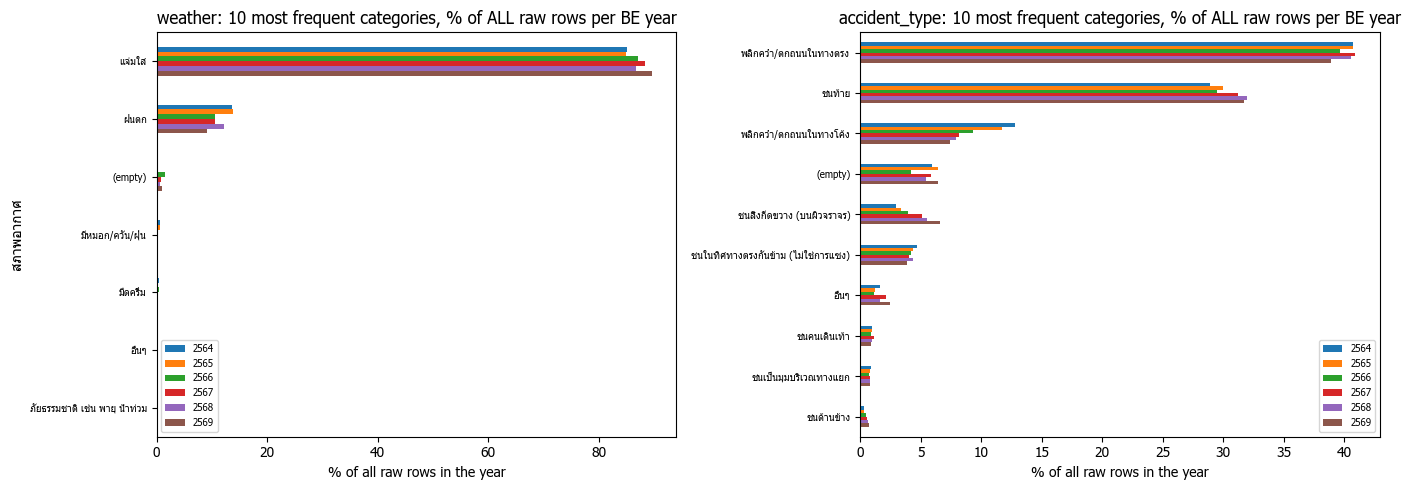

distinct reported provinces per year: {2564: 78, 2565: 78, 2566: 78, 2567: 78, 2568: 78, 2569: 79}


,2564,2565,2566,2567,2568,2569
สภาพอากาศ,,,,,,
แจ่มใส,17077,17459,20760,21155,20580,13652
ฝนตก,2745,2834,2540,2513,2905,1385
(empty),0,63,346,182,153,144
มีหมอก/ควัน/ฝุ่น,130,123,64,42,33,29
มืดครึ้ม,74,60,98,40,25,17
อื่นๆ,23,14,21,14,7,7
ภัยธรรมชาติ เช่น พายุ น้ำท่วม,13,13,12,6,12,5


In [7]:
cat_tables = {}
for field in ['province', 'weather', 'accident_type', 'presumed_cause', 'agency']:
    vc = pd.concat({y: pick(raw, AL[field]).replace('', '(empty)').value_counts() for y, raw in frames.items() if pick(raw, AL[field]) is not None}, axis=1).fillna(0).astype(int)
    vc = vc.loc[vc.sum(axis=1).sort_values(ascending=False).index]
    vc.to_csv(EDA / ('raw_category_' + field + '.csv'))
    cat_tables[field] = vc
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for a, field in zip(axes, ['weather', 'accident_type']):
    full = cat_tables[field]
    # denominator = ALL raw rows of that year (all categories incl. (empty)), so bars are true shares, not top-10-only shares
    (full.head(10) / full.sum() * 100).plot(kind='barh', ax=a, title=field + ': 10 most frequent categories, % of ALL raw rows per BE year')
    a.invert_yaxis(); a.legend(fontsize=7); a.tick_params(axis='y', labelsize=7); a.set_xlabel('% of all raw rows in the year')
fig.tight_layout(); fig.savefig(EDA / 'raw_category_shares.png', dpi=120); plt.show()
print('distinct reported provinces per year:', {y: int((cat_tables['province'][y] > 0).sum()) for y in cat_tables['province'].columns})
cat_tables['weather'].head(10)

In [8]:
assert int(overview['rows'].sum()) == sum(f['rows'] for f in MAN['files'])
assert (dfmt.sum() == overview['rows']).all() and (tfmt.sum() == overview['rows']).all()
assert (mon.sum() <= overview['rows']).all() and (hrs.sum() <= overview['rows']).all()
assert verify_hashes(OUT, MAN['files'], 'raw snapshot (post-EDA)') == 6
eda_summary = {'rows_by_year': overview['rows'].to_dict(), 'total_rows': int(overview['rows'].sum()),
               'slash_ambiguous_by_year': dfmt.loc['slash_ambiguous'].to_dict() if 'slash_ambiguous' in dfmt.index else {},
               'excel_serial_like_by_year': dfmt.loc['excel_serial_like'].to_dict() if 'excel_serial_like' in dfmt.index else {},
               'time_hh_mm_out_of_range_by_year': tfmt.loc['hh_mm_out_of_range'].to_dict() if 'hh_mm_out_of_range' in tfmt.index else {},
               'format_derived_month_rows_by_year': mon.sum().to_dict(), 'valid_hour_rows_by_year': hrs.sum().to_dict(),
               'note': 'raw snapshot EDA; not cleaned; month/hour are format-derived (real calendar date / clock time) but not the validated dates of notebook 03; zero reports != zero accidents; no causal claims'}
(EDA / 'eda_summary.json').write_text(json.dumps(eda_summary, ensure_ascii=False, indent=2, default=int), 'utf-8')
print(json.dumps(eda_summary, ensure_ascii=False, indent=1, default=int))

{
 "rows_by_year": {
  "2564": 20062,
  "2565": 20566,
  "2566": 23841,
  "2567": 23952,
  "2568": 23715,
  "2569": 15239
 },
 "total_rows": 127375,
 "slash_ambiguous_by_year": {
  "2564": 7413,
  "2565": 7268,
  "2566": 8295,
  "2567": 0,
  "2568": 0,
  "2569": 6034
 },
 "excel_serial_like_by_year": {
  "2564": 0,
  "2565": 0,
  "2566": 0,
  "2567": 23952,
  "2568": 23715,
  "2569": 0
 },
 "time_hh_mm_out_of_range_by_year": {},
 "format_derived_month_rows_by_year": {
  "2564": 12649,
  "2565": 13298,
  "2566": 15546,
  "2567": 23952,
  "2568": 23715,
  "2569": 9205
 },
 "valid_hour_rows_by_year": {
  "2564": 20062,
  "2565": 20566,
  "2566": 23841,
  "2567": 23952,
  "2568": 23715,
  "2569": 15239
 },
 "note": "raw snapshot EDA; not cleaned; month/hour are format-derived (real calendar date / clock time) but not the validated dates of notebook 03; zero reports != zero accidents; no causal claims"
}


## ข้อสังเกตและข้อจำกัด

- ตารางและกราฟทั้งหมดเป็น **ข้อมูลดิบ** ตัวเลขหลังทำความสะอาดอยู่ใน Notebook 03 (`reports/data/quality_report.json`)
- วันที่แบบ `d/m/yyyy` ที่ทั้งสองส่วน ≤ 12 และต่างกันเป็นวันที่กำกวม (`slash_ambiguous`) แม้จะมีหลักฐานลำดับวัน/เดือนจากแถวอื่นในไฟล์เดียวกัน เราไม่เลือกให้เองแบบเงียบ ๆ
- กราฟรายเดือนใช้เฉพาะเดือนที่ **ได้จากรูปแบบค่า** และประกอบเป็นวันที่จริงในปฏิทิน (เช่น `31/02` ถูกตัดออก) แต่ยังไม่ได้ตรวจว่าปีตรงกับไฟล์ จึงไม่ใช่ "วันที่ที่ parse แล้วว่าถูกต้อง" และมีอคติ (วันที่ 1–12 ของไฟล์ slash ถูกตัดออกมาก) ห้ามตีความเป็นฤดูกาลจริง
- กราฟรายชั่วโมงนับเฉพาะเวลาที่เป็นเวลาจริง (HH<24, MM<60, SS<60) หรือเศษส่วนวันของ Excel ที่ไม่ปัดเป็นเที่ยงคืนถัดไป; `24:00`, `12:99` ถูกจัดเป็น `hh_mm_out_of_range`
- กราฟสัดส่วนหมวดหมู่ใช้ตัวหารเป็น **จำนวนแถวดิบทั้งหมดของปีนั้น** (ทุกหมวดรวม `(empty)`) แสดงเฉพาะ 10 หมวดที่พบบ่อยที่สุด ผลรวมของแท่งจึงอาจน้อยกว่า 100%
- เวลา `0:00` ที่มีสัดส่วนสูงอาจเป็นค่าแทนเวลาที่ไม่ทราบ ยังไม่ได้ยืนยัน
- จำนวนรายงานเป็นศูนย์ ≠ ไม่มีอุบัติเหตุ; ความถี่ร่วมของหมวดหมู่ ≠ ความเป็นเหตุเป็นผล; ข้อมูลครอบคลุมเฉพาะถนนในระบบของกระทรวงคมนาคม
- การดูข้อมูลปี 2024–2026 ในขั้นนี้เป็นการพรรณนา และทำให้ข้อมูลเหล่านี้เป็นข้อมูลที่ถูกมองแล้ว (ไม่ใช่ test ที่ไม่เคยแตะ)